# โน้ตบุ๊ก 1: ทำความสะอาดข้อมูลการใช้ไฟฟ้าในสถานศึกษา (5 ขั้น)

## ตารางสรุปขั้นตอน
| ขั้น | ชื่อ | ทำอะไร | ผลลัพธ์ |
|---|---|---|---|
| 1 | ตรวจโครงสร้าง | คอลัมน์ ชนิดข้อมูล วันที่ ข้อมูลซ้ำ คีย์ ความสัมพันธ์ข้ามตาราง ช่วงค่า | ตัดแถวซ้ำ 100 แถว |
| 2 | จัดการค่าว่าง | หารูปแบบ เลือกวิธีเติม เทียบก่อน-หลัง | เติมค่าว่างด้วยค่ากลางของช่วงเวลาเดียวกัน |
| 3 | จัดการค่าผิดปกติ | ค่าติดลบ และค่าสูงผิดปกติ (ไม่ลบทิ้ง ติดป้ายและเก็บค่าเดิม) | ตารางค่าผิดปกติ + เทียบก่อน-หลัง |
| 4 | จัดมาตรฐาน | วันที่เวลา หมวดหมู่ รวมตาราง นิยามนอกเวลา กระทบยอด | ตารางสะอาดพร้อมวิเคราะห์ |
| 5 | พจนานุกรมและส่งออก | พจนานุกรมข้อมูล ขั้นตอนทำซ้ำ ไฟล์ตัวอย่าง | ไฟล์ใน data_clean |

## ตั้งค่าและโหลดข้อมูล

In [1]:
# setup: libraries, helpers and plotting style
import sys, os, platform
sys.path.append("../tools")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from helpers import setup_plot, explain, md, BLUE, BLUE_L, BLUE_D, GREY, RED, ORANGE
setup_plot()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

RAW, OUT = "../data_raw/", "../data_clean/"
os.makedirs(OUT, exist_ok=True)

# explicit encoding: source files are UTF-8 with BOM
elec = pd.read_csv(RAW + "electricity_hourly_raw.csv", encoding="utf-8-sig")
rooms = pd.read_csv(RAW + "rooms.csv", encoding="utf-8-sig")
meters = pd.read_csv(RAW + "meters.csv", encoding="utf-8-sig")
buildings = pd.read_csv(RAW + "buildings.csv", encoding="utf-8-sig")
weather = pd.read_csv(RAW + "weather_hourly.csv", encoding="utf-8-sig")
dd_raw = pd.read_csv(RAW + "data_dictionary.csv", encoding="utf-8-sig")
print({"electricity": elec.shape, "rooms": rooms.shape, "meters": meters.shape,
       "buildings": buildings.shape, "weather": weather.shape})

# cleaning log: every issue found and what was done about it
LOG = []
def add_log(step, issue, n, action):
    LOG.append({"step": step, "issue": issue, "rows_affected": int(n), "action": action})

{'electricity': (350500, 5), 'rooms': (40, 6), 'meters': (40, 3), 'buildings': (5, 2), 'weather': (8760, 3)}


# ขั้นที่ 1 ตรวจโครงสร้าง

## 1.1 คอลัมน์ ชนิดข้อมูล และวันที่เวลา

In [2]:
# expected columns come from the provided data_dictionary.csv
expected = dd_raw[dd_raw["file"] == "electricity_hourly_raw.csv"]["column"].tolist()
print("missing columns:", [c for c in expected if c not in elec.columns],
      "| extra columns:", [c for c in elec.columns if c not in expected])
print(elec.dtypes.to_string())

# parse timestamps strictly (bad values become NaT so they are counted, never hidden)
elec["timestamp"] = pd.to_datetime(elec["timestamp"], errors="coerce")
weather["timestamp"] = pd.to_datetime(weather["timestamp"], errors="coerce")
print("bad timestamps electricity:", int(elec["timestamp"].isna().sum()), "| weather:", int(weather["timestamp"].isna().sum()))
print("range:", elec["timestamp"].min(), "->", elec["timestamp"].max())
add_log(1, "timestamp cannot be parsed", elec["timestamp"].isna().sum(), "none found")

missing columns: [] | extra columns: []
reading_id              str
timestamp               str
meter_id                str
energy_kwh          float64
occupancy_people      int64
bad timestamps electricity: 0 | weather: 0
range: 2025-01-01 00:00:00 -> 2025-12-31 23:00:00


## 1.2 ข้อมูลซ้ำ และคีย์หลัก

In [3]:
# duplicates: exact rows, primary key, (timestamp, meter) pair
n_raw = len(elec)
raw_total_kwh = elec["energy_kwh"].sum()   # total including duplicates (NaN skipped)
dup_rows = int(elec.duplicated().sum())
dup_key = int(elec["reading_id"].duplicated().sum())
dup_pair = int(elec.duplicated(["timestamp", "meter_id"]).sum())
all_copies = dup_rows == dup_key == dup_pair
print("exact duplicate rows:", dup_rows, "| duplicate reading_id:", dup_key, "| duplicate (timestamp, meter):", dup_pair)
print("all duplicates are exact copies:", all_copies, "| rate: %.4f%% of %d rows" % (100 * dup_rows / n_raw, n_raw))

rows_per_meter_before = elec.groupby("meter_id").size()
dup_meters = rows_per_meter_before[rows_per_meter_before > 8760]
print("meters that hold duplicates:", dup_meters.to_dict())

dup_kwh = elec[elec.duplicated()]["energy_kwh"].sum()
elec = elec.drop_duplicates().copy()          # keep first copy, original index kept for traceability
assert elec["reading_id"].is_unique
print("after drop:", len(elec), "rows | primary key unique:", elec["reading_id"].is_unique)
add_log(1, "duplicate rows (exact copies)", dup_rows, "dropped, kept first copy")

exact duplicate rows: 100 | duplicate reading_id: 100 | duplicate (timestamp, meter): 100
all duplicates are exact copies: True | rate: 0.0285% of 350500 rows
meters that hold duplicates: {'M001': 8780, 'M009': 8780, 'M017': 8780, 'M025': 8780, 'M033': 8780}


after drop: 350400 rows | primary key unique: True


## 1.3 ความสัมพันธ์ข้ามตาราง และความครบถ้วนของเวลา

In [4]:
# foreign-key match rates (rubric target >= 99%)
fk = {"electricity.meter_id -> meters": elec["meter_id"].isin(meters["meter_id"]).mean(),
      "meters.room_id -> rooms": meters["room_id"].isin(rooms["room_id"]).mean(),
      "rooms.building_id -> buildings": rooms["building_id"].isin(buildings["building_id"]).mean(),
      "electricity.timestamp -> weather": elec["timestamp"].isin(weather["timestamp"]).mean()}
fk_table = pd.DataFrame({"match_rate_pct": {k: round(100 * v, 2) for k, v in fk.items()}})
fk_table["pass_99pct"] = fk_table["match_rate_pct"] >= 99
display(fk_table)

# completeness: one row per meter per hour
per_meter = elec.groupby("meter_id").size()
expected_hours = len(weather)
complete = int((per_meter == expected_hours).sum())
print("expected hours per meter:", expected_hours, "| complete meters:", complete, "of", per_meter.size)
print("one reading per meter-hour:", not elec.duplicated(["timestamp", "meter_id"]).any())

,match_rate_pct,pass_99pct
electricity.meter_id -> meters,100.0,True
meters.room_id -> rooms,100.0,True
rooms.building_id -> buildings,100.0,True
electricity.timestamp -> weather,100.0,True


expected hours per meter: 8760 | complete meters: 40 of 40
one reading per meter-hour: True


## 1.4 ช่วงค่าที่สมเหตุสมผล (domain check)

In [5]:
# plausibility checks on every numeric column
chk = elec.merge(meters, on="meter_id").merge(rooms, on="room_id")
rows = [
    ("energy_kwh", "kWh per hour", chk["energy_kwh"].min(), chk["energy_kwh"].max(), "negative values: %d" % (chk["energy_kwh"] < 0).sum()),
    ("occupancy_people", "people", chk["occupancy_people"].min(), chk["occupancy_people"].max(), "above room capacity: %d" % (chk["occupancy_people"] > chk["capacity_people"]).sum()),
    ("temperature_c", "deg C", weather["temperature_c"].min(), weather["temperature_c"].max(), "missing: %d" % weather["temperature_c"].isna().sum()),
    ("relative_humidity_percent", "%", weather["relative_humidity_percent"].min(), weather["relative_humidity_percent"].max(),
     "outside 0-100: %d" % ((weather["relative_humidity_percent"] < 0) | (weather["relative_humidity_percent"] > 100)).sum()),
    ("area_m2", "m2", rooms["area_m2"].min(), rooms["area_m2"].max(), "non-positive: %d" % (rooms["area_m2"] <= 0).sum()),
    ("air_conditioner_count", "units", rooms["air_conditioner_count"].min(), rooms["air_conditioner_count"].max(), "non-positive: %d" % (rooms["air_conditioner_count"] <= 0).sum()),
]
domain = pd.DataFrame(rows, columns=["column", "unit", "min", "max", "check"])
display(domain)
missing_key_pct = elec[["reading_id", "timestamp", "meter_id"]].isna().mean().max() * 100
print("missing key fields (max over keys): %.3f%% (rubric <= 1%%)" % missing_key_pct)

,column,unit,min,max,check
0,energy_kwh,kWh per hour,-0.5,109.56,negative values: 18
1,occupancy_people,people,0.0,40.00,above room capacity: 0
2,temperature_c,deg C,19.5,38.40,missing: 0
3,relative_humidity_percent,%,44.0,100.00,outside 0-100: 0
4,area_m2,m2,47.0,120.00,non-positive: 0
5,air_conditioner_count,units,1.0,3.00,non-positive: 0


missing key fields (max over keys): 0.000% (rubric <= 1%)


## 1.5 กราฟ: จำนวนแถวต่อมิเตอร์ ก่อนตัดข้อมูลซ้ำ

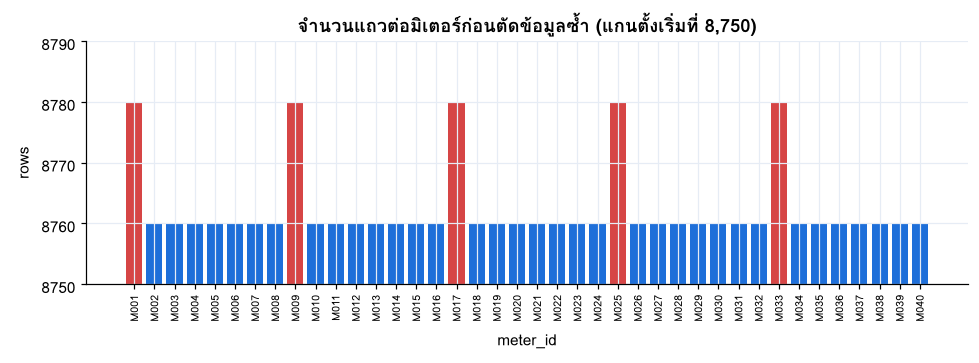

> **สรุปสั้น (n=350500):** ข้อมูลซ้ำ 100 แถวจาก 350,500 แถว กระจุกอยู่ใน 5 มิเตอร์ ตัดออกแล้วทุกมิเตอร์ครบ 8,760 ชั่วโมง

<details><summary><b>▶ ดูรายละเอียดการวิเคราะห์ (กดเปิด/ปิด)</b></summary>

**🔍 สิ่งที่พบ:** แถวซ้ำเป็นสำเนาเหมือนกันทุกประการ 100 แถว (0.029%) อยู่ในมิเตอร์ M001, M009, M017, M025, M033 มิเตอร์ละ 20 แถว หลังตัดแล้วเหลือ 350,400 แถว ทุกตารางเชื่อมกันได้ 100%

**💡 ความหมาย:** ถ้าไม่ตัดแถวซ้ำ ยอดรวมของมิเตอร์ทั้ง 5 ตัวจะสูงเกินจริง รวม 84.58 kWh

**🎯 ข้อเสนอแนะ:** ตรวจระบบบันทึกข้อมูลของมิเตอร์ที่มีแถวซ้ำ (ผู้รับผิดชอบ: ผู้ดูแลระบบมิเตอร์ ภายใน 1 สัปดาห์)

- ใช้ดูอะไร: ดูว่าข้อมูลมีแถวซ้ำที่มิเตอร์ไหนบ้าง
- อ่านอย่างไร: แท่งสีแดงคือมิเตอร์ที่มีแถวเกิน 8,760 (1 ปี x 24 ชั่วโมง) ส่วนสีน้ำเงินปกติ
- วิเคราะห์ด้วยวิธี: นับแถวซ้ำแบบตรงกันทุกคอลัมน์ เทียบคีย์หลัก reading_id และคู่ (เวลา, มิเตอร์)

</details>

In [6]:
# chart: rows per meter before dropping duplicates (axis cut on purpose and stated in the title note)
fig, ax = plt.subplots(figsize=(9, 3.4))
colors = [RED if v > 8760 else BLUE for v in rows_per_meter_before.values]
ax.bar(rows_per_meter_before.index, rows_per_meter_before.values, color=colors)
ax.set_ylim(8750, rows_per_meter_before.max() + 10)
ax.set_title("จำนวนแถวต่อมิเตอร์ก่อนตัดข้อมูลซ้ำ (แกนตั้งเริ่มที่ 8,750)")
ax.set_xlabel("meter_id"); ax.set_ylabel("rows")
ax.tick_params(axis="x", rotation=90, labelsize=7)
plt.tight_layout(); plt.show()

explain(
    short="ข้อมูลซ้ำ %d แถวจาก %s แถว กระจุกอยู่ใน %d มิเตอร์ ตัดออกแล้วทุกมิเตอร์ครบ %s ชั่วโมง" % (dup_rows, format(n_raw, ","), len(dup_meters), format(expected_hours, ",")),
    found="แถวซ้ำเป็นสำเนาเหมือนกันทุกประการ %d แถว (%.3f%%) อยู่ในมิเตอร์ %s มิเตอร์ละ %s แถว หลังตัดแล้วเหลือ %s แถว ทุกตารางเชื่อมกันได้ 100%%" % (dup_rows, 100 * dup_rows / n_raw, ", ".join(dup_meters.index), ", ".join(sorted(set(str(v - 8760) for v in dup_meters.values))), format(len(elec), ",")),
    meaning="ถ้าไม่ตัดแถวซ้ำ ยอดรวมของมิเตอร์ทั้ง %d ตัวจะสูงเกินจริง รวม %.2f kWh" % (len(dup_meters), dup_kwh),
    action="ตรวจระบบบันทึกข้อมูลของมิเตอร์ที่มีแถวซ้ำ (ผู้รับผิดชอบ: ผู้ดูแลระบบมิเตอร์ ภายใน 1 สัปดาห์)",
    use="ดูว่าข้อมูลมีแถวซ้ำที่มิเตอร์ไหนบ้าง", read="แท่งสีแดงคือมิเตอร์ที่มีแถวเกิน 8,760 (1 ปี x 24 ชั่วโมง) ส่วนสีน้ำเงินปกติ",
    method="นับแถวซ้ำแบบตรงกันทุกคอลัมน์ เทียบคีย์หลัก reading_id และคู่ (เวลา, มิเตอร์)", n=n_raw)

# ขั้นที่ 2 จัดการค่าว่าง

## 2.1 หาค่าว่างและรูปแบบการขาดหาย

In [7]:
# count missing values per column (all tables)
miss_tbl = pd.DataFrame({"table": ["electricity"] * 5,
                         "column": elec.columns.tolist(),
                         "missing": [int(elec[c].isna().sum()) for c in elec.columns]})
miss_tbl["missing_pct"] = (100 * miss_tbl["missing"] / len(elec)).round(4)
display(miss_tbl)
print("missing in other tables:", {"rooms": int(rooms.isna().sum().sum()), "meters": int(meters.isna().sum().sum()),
                                   "buildings": int(buildings.isna().sum().sum()), "weather": int(weather.isna().sum().sum())})

# helper columns used for the rule "same meter, same hour of day, same day type"
elec["hour"] = elec["timestamp"].dt.hour
elec["is_weekday"] = elec["timestamp"].dt.dayofweek < 5

# pattern of missing rows: which meters, how many per meter, regular spacing of row positions?
na_rows = elec[elec["energy_kwh"].isna()]
per_meter_na = na_rows.groupby("meter_id").size()
gaps = np.diff(na_rows.index.values)
print("missing rows:", len(na_rows), "| meters affected:", per_meter_na.size, "| max per meter:", int(per_meter_na.max()))
print("row-position gaps between missing rows:", pd.Series(gaps).value_counts().to_dict())
print("share of missing rows in weekday 08-16:", round(float(((na_rows["hour"].between(8, 16)) & na_rows["is_weekday"]).mean()), 3))

,table,column,missing,missing_pct
0,electricity,reading_id,0,0.00
1,electricity,timestamp,0,0.00
2,electricity,meter_id,0,0.00
3,electricity,energy_kwh,35,0.01
4,electricity,occupancy_people,0,0.00


missing in other tables: {'rooms': 0, 'meters': 0, 'buildings': 0, 'weather': 0}
missing rows: 35 | meters affected: 35 | max per meter: 1
row-position gaps between missing rows: {10001: 34}
share of missing rows in weekday 08-16: 0.314


## 2.2 เลือกวิธีเติมค่าว่าง

In [8]:
# strategy: fill with the median of the same meter x hour-of-day x weekday/weekend (domain-based)
# reason: usage follows a daily and weekly schedule, so a global mean would be wrong for both day and night
valid = elec["energy_kwh"].where(elec["energy_kwh"] >= 0)       # negatives are invalid, never used as a reference
CELL = ["meter_id", "hour", "is_weekday"]
elec["cell_median"] = valid.groupby([elec[c] for c in CELL]).transform("median")
print("cells without reference:", int(elec["cell_median"].isna().sum()))

elec["energy_clean"] = elec["energy_kwh"]                       # raw value kept in energy_kwh
elec["flag_missing"] = elec["energy_kwh"].isna()
elec.loc[elec["flag_missing"], "energy_clean"] = elec.loc[elec["flag_missing"], "cell_median"]

# alternative for comparison: average of previous and next hour of the same meter
srt = elec.sort_values(["meter_id", "timestamp"])
nbr = (srt.groupby("meter_id")["energy_kwh"].shift(1) + srt.groupby("meter_id")["energy_kwh"].shift(-1)) / 2
alt = nbr[srt["flag_missing"]]
cmp_tbl = pd.DataFrame({"cell_median": srt.loc[srt["flag_missing"], "cell_median"], "neighbour_avg": alt})
cmp_tbl["abs_diff"] = (cmp_tbl["cell_median"] - cmp_tbl["neighbour_avg"]).abs()
print("mean abs difference between the two methods (kWh):", round(float(cmp_tbl["abs_diff"].mean()), 4),
      "| max:", round(float(cmp_tbl["abs_diff"].max()), 4), "| n:", int(cmp_tbl["abs_diff"].notna().sum()))
add_log(2, "energy_kwh missing", elec["flag_missing"].sum(), "filled with median of same meter x hour x day type")

cells without reference: 0
mean abs difference between the two methods (kWh): 0.2236 | max: 1.6295 | n: 35


## 2.3 เทียบก่อน-หลังเติมค่าว่าง และกราฟ

,before_fill,after_fill,change_pct
n,350347.000000,350382.000000,0.0100
total_kWh,275164.399000,275195.346500,0.0112
mean_kWh,0.785405,0.785415,0.0013
median_kWh,0.087000,0.087000,0.0000


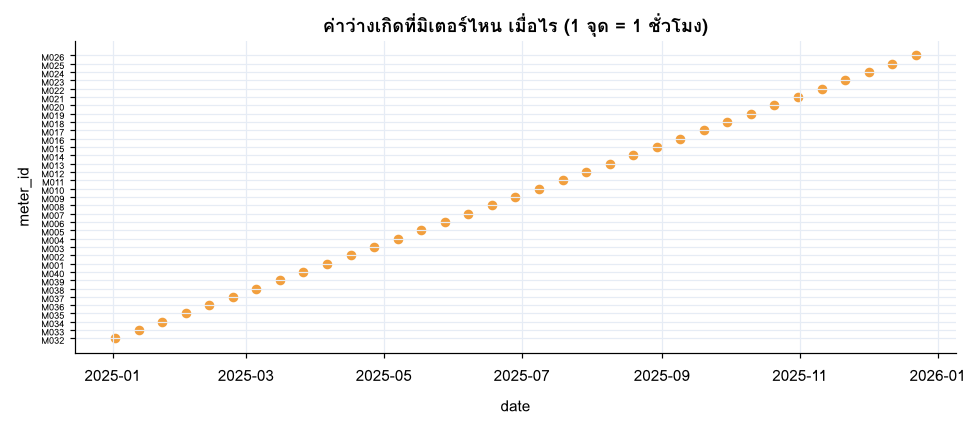

> **สรุปสั้น (n=350400):** ค่าว่าง 35 จุด (0.0100%) กระจายใน 35 มิเตอร์ เติมแล้วยอดรวมเปลี่ยน 0.0112%

<details><summary><b>▶ ดูรายละเอียดการวิเคราะห์ (กดเปิด/ปิด)</b></summary>

**🔍 สิ่งที่พบ:** ค่าว่างมีเฉพาะคอลัมน์ energy_kwh (35 แถว) แต่ละมิเตอร์ขาดไม่เกิน 1 ชั่วโมง ไม่มีมิเตอร์ใดขาดต่อเนื่อง ระยะห่างของตำแหน่งแถวที่ขาดมีรูปแบบสม่ำเสมอ ({10001: 34}) ซึ่งสอดคล้องกับข้อมูลที่ระบุว่าจำลองขึ้น

**💡 ความหมาย:** สัดส่วนที่ขาดต่ำกว่าเกณฑ์ 5% ของฟีเจอร์สำคัญมาก จึงเติมได้โดยไม่กระทบสถิติ (ค่าเฉลี่ยเปลี่ยน 0.0013%) วิธีเติมแบบค่ากลางของช่วงเวลาเดียวกันต่างจากการเฉลี่ยชั่วโมงข้างเคียงเฉลี่ย 0.224 kWh

**🎯 ข้อเสนอแนะ:** ตรวจว่าทำไมระบบบันทึกข้อมูลขาด 1 ชั่วโมงในแต่ละมิเตอร์ (ผู้รับผิดชอบ: ผู้ดูแลระบบมิเตอร์ ภายใน 1 เดือน)

- ใช้ดูอะไร: ดูว่าข้อมูลขาดที่ไหนและเมื่อไร
- อ่านอย่างไร: จุดสีส้มแต่ละจุดคือชั่วโมงที่ไม่มีค่าของมิเตอร์นั้น ถ้าเรียงเป็นกลุ่มแปลว่าขาดต่อเนื่อง
- วิเคราะห์ด้วยวิธี: นับค่าว่างรายคอลัมน์ เติมด้วยค่ามัธยฐานของมิเตอร์เดียวกัน ชั่วโมงเดียวกัน วันทำการ/วันหยุดเหมือนกัน เทียบก่อนหลัง

</details>

In [9]:
# before / after statistics
before = elec["energy_kwh"].where(elec["energy_kwh"] >= 0)
after = elec["energy_clean"].where(elec["energy_clean"] >= 0)
stat = pd.DataFrame({"before_fill": [before.count(), before.sum(), before.mean(), before.median()],
                     "after_fill": [after.count(), after.sum(), after.mean(), after.median()]},
                    index=["n", "total_kWh", "mean_kWh", "median_kWh"])
stat["change_pct"] = (100 * (stat["after_fill"] / stat["before_fill"] - 1)).round(4)
display(stat)

# chart: when and where values are missing (each dot = 1 missing hour)
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(na_rows["timestamp"], na_rows["meter_id"], color=ORANGE, s=28)
ax.set_title("ค่าว่างเกิดที่มิเตอร์ไหน เมื่อไร (1 จุด = 1 ชั่วโมง)")
ax.set_xlabel("date"); ax.set_ylabel("meter_id"); ax.tick_params(axis="y", labelsize=6)
plt.tight_layout(); plt.show()

explain(
    short="ค่าว่าง %d จุด (%.4f%%) กระจายใน %d มิเตอร์ เติมแล้วยอดรวมเปลี่ยน %.4f%%" % (len(na_rows), 100 * len(na_rows) / len(elec), per_meter_na.size, stat.loc["total_kWh", "change_pct"]),
    found="ค่าว่างมีเฉพาะคอลัมน์ energy_kwh (%d แถว) แต่ละมิเตอร์ขาดไม่เกิน %d ชั่วโมง ไม่มีมิเตอร์ใดขาดต่อเนื่อง ระยะห่างของตำแหน่งแถวที่ขาดมีรูปแบบสม่ำเสมอ (%s) ซึ่งสอดคล้องกับข้อมูลที่ระบุว่าจำลองขึ้น" % (len(na_rows), int(per_meter_na.max()), pd.Series(gaps).value_counts().head(2).to_dict()),
    meaning="สัดส่วนที่ขาดต่ำกว่าเกณฑ์ 5%% ของฟีเจอร์สำคัญมาก จึงเติมได้โดยไม่กระทบสถิติ (ค่าเฉลี่ยเปลี่ยน %.4f%%) วิธีเติมแบบค่ากลางของช่วงเวลาเดียวกันต่างจากการเฉลี่ยชั่วโมงข้างเคียงเฉลี่ย %.3f kWh" % (stat.loc["mean_kWh", "change_pct"], cmp_tbl["abs_diff"].mean()),
    action="ตรวจว่าทำไมระบบบันทึกข้อมูลขาด 1 ชั่วโมงในแต่ละมิเตอร์ (ผู้รับผิดชอบ: ผู้ดูแลระบบมิเตอร์ ภายใน 1 เดือน)",
    use="ดูว่าข้อมูลขาดที่ไหนและเมื่อไร", read="จุดสีส้มแต่ละจุดคือชั่วโมงที่ไม่มีค่าของมิเตอร์นั้น ถ้าเรียงเป็นกลุ่มแปลว่าขาดต่อเนื่อง",
    method="นับค่าว่างรายคอลัมน์ เติมด้วยค่ามัธยฐานของมิเตอร์เดียวกัน ชั่วโมงเดียวกัน วันทำการ/วันหยุดเหมือนกัน เทียบก่อนหลัง", n=len(elec))

# ขั้นที่ 3 จัดการค่าผิดปกติ

## 3.1 ค่าติดลบ

In [10]:
# negative energy is physically impossible for an hourly energy reading
neg = elec["energy_kwh"] < 0
print("negative rows:", int(neg.sum()), "| distinct negative values:", sorted(elec.loc[neg, "energy_kwh"].unique().tolist()))
print("negative rows by meter:", elec[neg].groupby("meter_id").size().to_dict())
elec["flag_negative"] = neg
elec.loc[neg, "energy_clean"] = elec.loc[neg, "cell_median"]
add_log(3, "negative energy_kwh (all equal -0.5, looks like an error code)", neg.sum(), "treated as invalid, replaced by cell median, flag kept")

negative rows: 18 | distinct negative values: [-0.5]
negative rows by meter: {'M001': 1, 'M004': 1, 'M007': 1, 'M010': 1, 'M013': 1, 'M016': 1, 'M019': 1, 'M022': 1, 'M023': 1, 'M025': 1, 'M026': 1, 'M028': 1, 'M029': 1, 'M031': 1, 'M032': 1, 'M034': 1, 'M035': 1, 'M038': 1}


## 3.2 ค่าสูงผิดปกติ: เลือกเกณฑ์

In [11]:
# why not one global IQR rule? usage is bimodal (day vs night), so a global rule would flag normal working hours
v = elec["energy_kwh"].where(elec["energy_kwh"] >= 0)
gq1, gq3 = v.quantile(0.25), v.quantile(0.75)
global_flag = v > gq3 + 1.5 * (gq3 - gq1)
print("global IQR rule would flag:", int(global_flag.sum()), "rows (%.1f%% of data)" % (100 * global_flag.mean()))

# chosen rule: compare each value with its own cell (meter x hour x day type)
grp = v.groupby([elec[c] for c in CELL])
q1 = grp.transform(lambda s: s.quantile(0.25))
q3 = grp.transform(lambda s: s.quantile(0.75))
iqr = q3 - q1
rule_iqr = v > q3 + 3 * iqr                       # far above the cell spread
rule_ratio = v > 3 * elec["cell_median"]          # and at least 3x the cell median (business sense)
elec["flag_outlier"] = (rule_iqr & rule_ratio).fillna(False)
print("rule A (above Q3 + 3*IQR of its cell):", int(rule_iqr.sum()), "| rule B (also > 3x cell median):", int(elec["flag_outlier"].sum()))
print("rows flagged outlier:", int(elec["flag_outlier"].sum()))

global IQR rule would flag: 9208 rows (2.6% of data)


rule A (above Q3 + 3*IQR of its cell): 21 | rule B (also > 3x cell median): 21
rows flagged outlier: 21


## 3.3 ตรวจว่าเป็นข้อมูลผิดพลาดหรือเหตุการณ์จริง และจัดทำตารางค่าผิดปกติ

In [12]:
# evidence table: size vs normal, isolated or sustained?, occupancy at that hour
srt = elec.sort_values(["meter_id", "timestamp"])
prev_v = srt.groupby("meter_id")["energy_kwh"].shift(1).reindex(elec.index)
next_v = srt.groupby("meter_id")["energy_kwh"].shift(-1).reindex(elec.index)
info = elec.merge(meters, on="meter_id", how="left").merge(rooms, on="room_id", how="left")
info.index = elec.index
out = info[elec["flag_outlier"]].copy()
out["ratio_to_normal"] = (out["energy_kwh"] / out["cell_median"]).round(1)
out["prev_hour"] = prev_v[out.index]
out["next_hour"] = next_v[out.index]
out["isolated"] = (out["prev_hour"] < 2 * out["cell_median"]) & (out["next_hour"] < 2 * out["cell_median"])
out_log = out[["timestamp", "meter_id", "room_id", "building_id", "room_type", "energy_kwh", "cell_median",
               "ratio_to_normal", "prev_hour", "next_hour", "isolated", "occupancy_people"]].sort_values("energy_kwh", ascending=False)
out_log = out_log.rename(columns={"energy_kwh": "value_kwh", "cell_median": "normal_kwh"})
display(out_log.head(25))
print("outliers:", len(out_log), "| isolated single-hour spikes:", int(out_log["isolated"].sum()),
      "| ratio range: %.1f - %.1f x normal" % (out_log["ratio_to_normal"].min(), out_log["ratio_to_normal"].max()))
print("occupancy at those hours (min/median/max):", int(out_log["occupancy_people"].min()), out_log["occupancy_people"].median(), int(out_log["occupancy_people"].max()))

# occupancy plausibility
print("occupancy above capacity:", int((info["occupancy_people"] > info["capacity_people"]).sum()))

# handling: NOT deleted. raw value kept, clean column uses the cell median, row carries a flag
elec.loc[elec["flag_outlier"], "energy_clean"] = elec.loc[elec["flag_outlier"], "cell_median"]
elec["flag_imputed"] = elec["flag_missing"] | elec["flag_negative"] | elec["flag_outlier"]
add_log(3, "isolated spikes %.0f-%.0fx normal (rule: Q3+3*IQR of cell and >3x cell median)" % (out_log["ratio_to_normal"].min(), out_log["ratio_to_normal"].max()), elec["flag_outlier"].sum(),
        "kept in outliers_log.csv with raw value; replaced by cell median in energy_clean; needs meter check")

,timestamp,meter_id,room_id,building_id,room_type,value_kwh,normal_kwh,ratio_to_normal,prev_hour,next_hour,isolated,occupancy_people
173443,2025-06-30 16:00:00,M004,B01-R04,B01,สำนักงาน,109.56,3.4320,31.9,3.595,0.091,True,21
190454,2025-07-18 09:00:00,M015,B02-R07,B02,ห้องเรียน,81.57,3.1350,26.0,3.469,3.005,True,10
122410,2025-05-08 12:00:00,M011,B02-R03,B02,ห้องปฏิบัติการ,74.19,2.5440,29.2,2.573,2.984,True,7
309531,2025-11-19 10:00:00,M012,B02-R04,B02,สำนักงาน,60.96,2.5520,23.9,2.028,1.948,True,14
54366,2025-02-26 15:00:00,M007,B01-R07,B01,ห้องเรียน,54.90,1.8050,30.4,2.161,2.157,True,9
241487,2025-09-09 13:00:00,M008,B01-R08,B01,ห้องเก็บอุปกรณ์,53.04,1.8760,28.3,1.553,2.063,True,30
71377,2025-03-16 08:00:00,M018,B03-R02,B03,ห้องคอมพิวเตอร์,7.56,0.2640,28.6,0.231,0.261,True,0
343553,2025-12-24 20:00:00,M034,B05-R02,B05,ห้องคอมพิวเตอร์,7.47,0.2620,28.5,0.232,0.266,True,0
207465,2025-08-05 02:00:00,M026,B04-R02,B04,ห้องคอมพิวเตอร์,7.35,0.2600,28.3,0.258,0.273,True,0
3333,2025-01-04 11:00:00,M014,B02-R06,B02,ห้องสมุด,2.73,0.0815,33.5,0.091,0.081,True,0


outliers: 21 | isolated single-hour spikes: 21 | ratio range: 23.9 - 34.2 x normal
occupancy at those hours (min/median/max): 0 0.0 30
occupancy above capacity: 0


## 3.4 เทียบก่อน-หลัง และกราฟ

,before,after,change_pct
n,350347.000000,350400.000000,0.015
total_kWh,275164.399000,274748.343500,-0.151
mean_kWh,0.785405,0.784099,-0.166
std_kWh,1.207209,1.167353,-3.301
max_kWh,109.560000,4.941000,-95.490


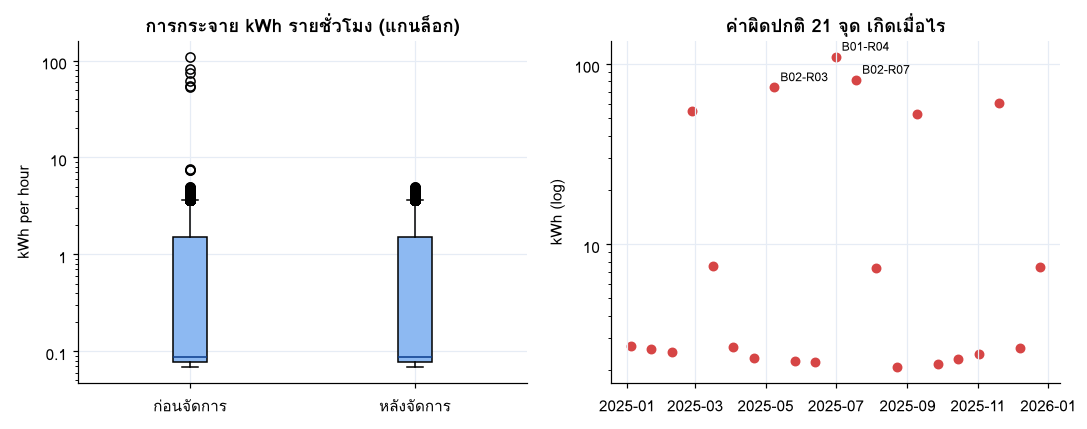

> **สรุปสั้น (n=350400):** พบค่าสูงผิดปกติ 21 จุด (0.0060%) จัดการแล้วยอดรวม (เทียบเฉพาะค่าที่ใช้ได้ก่อนหน้า) ลด 0.151% (416.1 kWh)

<details><summary><b>▶ ดูรายละเอียดการวิเคราะห์ (กดเปิด/ปิด)</b></summary>

**🔍 สิ่งที่พบ:** ค่าผิดปกติสูงกว่าปกติของช่วงเวลาเดียวกัน 23.9-34.2 เท่า เกิดเป็นชั่วโมงเดียวโดดๆ 21 จาก 21 จุด และจำนวนคนในชั่วโมงนั้นอยู่ในช่วงปกติ (0-30 คน) ค่าติดลบ 18 แถวเท่ากับ -0.5 ทุกแถว จึงน่าจะเป็นรหัสแทนค่าเสียของมิเตอร์ ไม่ใช่ค่าจริง

**💡 ความหมาย:** ลักษณะนี้เข้าได้กับข้อมูลวัดผิดพลาด แต่ข้อมูลยังบอกไม่ได้ว่าเป็นความผิดพลาดหรือเหตุการณ์จริง จึงไม่ลบทิ้ง เก็บค่าเดิมไว้ในตาราง และใช้ค่าปกติของช่วงเวลาเดียวกันแทนในการวิเคราะห์ ถ้าไม่จัดการ ค่าสูงสุดจะเป็น 109.6 kWh ทั้งที่ค่าปกติอยู่ราว 0.1-3.5 kWh

**🎯 ข้อเสนอแนะ:** ให้ผู้ดูแลมิเตอร์ตรวจย้อนหลังตามวันเวลาในตาราง outliers_log.csv ภายใน 2 สัปดาห์ ถ้ายืนยันว่าเป็นเหตุการณ์จริงให้ใส่ค่าเดิมกลับ

- ใช้ดูอะไร: ดูว่าค่าผิดปกติมากแค่ไหน เกิดเมื่อไร และการจัดการกระทบยอดรวมอย่างไร
- อ่านอย่างไร: กราฟซ้าย: กล่องก่อนหลังเปรียบเทียบ ถ้าหนวดบนสั้นลงมากแปลว่าตัดค่าสูงผิดปกติออกแล้ว กราฟขวา: แต่ละจุดคือค่าผิดปกติหนึ่งจุด
- วิเคราะห์ด้วยวิธี: เทียบแต่ละค่ากับกลุ่มของตัวเอง (มิเตอร์ x ชั่วโมง x วันทำการ/วันหยุด) ต้องสูงกว่า Q3+3xIQR และสูงกว่า 3 เท่าของค่ากลาง

</details>

In [13]:
# before / after on key statistics
b = elec["energy_kwh"].where(elec["energy_kwh"] >= 0)
a = elec["energy_clean"]
ba = pd.DataFrame({"before": [b.count(), b.sum(), b.mean(), b.std(), b.max()],
                   "after": [a.count(), a.sum(), a.mean(), a.std(), a.max()]},
                  index=["n", "total_kWh", "mean_kWh", "std_kWh", "max_kWh"])
ba["change_pct"] = (100 * (ba["after"] / ba["before"] - 1)).round(3)
display(ba)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].boxplot([b.dropna(), a], tick_labels=["ก่อนจัดการ", "หลังจัดการ"], patch_artist=True,
                boxprops=dict(facecolor=BLUE_L), medianprops=dict(color=BLUE_D))
from matplotlib.ticker import FuncFormatter, NullFormatter
plain = FuncFormatter(lambda val, _: "%g" % val)
axes[0].set_yscale("log"); axes[0].yaxis.set_major_formatter(plain); axes[0].yaxis.set_minor_formatter(NullFormatter()); axes[0].set_title("การกระจาย kWh รายชั่วโมง (แกนล็อก)"); axes[0].set_ylabel("kWh per hour")
axes[1].scatter(out_log["timestamp"], out_log["value_kwh"], color=RED, s=30)
for _, r in out_log.head(3).iterrows():
    axes[1].annotate(r["room_id"], (r["timestamp"], r["value_kwh"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
axes[1].set_yscale("log"); axes[1].yaxis.set_major_formatter(plain); axes[1].yaxis.set_minor_formatter(NullFormatter()); axes[1].set_title("ค่าผิดปกติ %d จุด เกิดเมื่อไร" % len(out_log)); axes[1].set_ylabel("kWh (log)")
plt.tight_layout(); plt.show()

by_b = out_log.groupby("building_id").size().sort_values(ascending=False)
explain(
    short="พบค่าสูงผิดปกติ %d จุด (%.4f%%) จัดการแล้วยอดรวม (เทียบเฉพาะค่าที่ใช้ได้ก่อนหน้า) ลด %.3f%% (%.1f kWh)" % (len(out_log), 100 * len(out_log) / len(elec), -ba.loc["total_kWh", "change_pct"], ba.loc["total_kWh", "before"] - ba.loc["total_kWh", "after"]),
    found="ค่าผิดปกติสูงกว่าปกติของช่วงเวลาเดียวกัน %.1f-%.1f เท่า เกิดเป็นชั่วโมงเดียวโดดๆ %d จาก %d จุด และจำนวนคนในชั่วโมงนั้นอยู่ในช่วงปกติ (%d-%d คน) ค่าติดลบ %d แถวเท่ากับ -0.5 ทุกแถว จึงน่าจะเป็นรหัสแทนค่าเสียของมิเตอร์ ไม่ใช่ค่าจริง" % (out_log["ratio_to_normal"].min(), out_log["ratio_to_normal"].max(), out_log["isolated"].sum(), len(out_log), out_log["occupancy_people"].min(), out_log["occupancy_people"].max(), int(neg.sum())),
    meaning="ลักษณะนี้เข้าได้กับข้อมูลวัดผิดพลาด แต่ข้อมูลยังบอกไม่ได้ว่าเป็นความผิดพลาดหรือเหตุการณ์จริง จึงไม่ลบทิ้ง เก็บค่าเดิมไว้ในตาราง และใช้ค่าปกติของช่วงเวลาเดียวกันแทนในการวิเคราะห์ ถ้าไม่จัดการ ค่าสูงสุดจะเป็น %.1f kWh ทั้งที่ค่าปกติอยู่ราว 0.1-3.5 kWh" % ba.loc["max_kWh", "before"],
    action="ให้ผู้ดูแลมิเตอร์ตรวจย้อนหลังตามวันเวลาในตาราง outliers_log.csv ภายใน 2 สัปดาห์ ถ้ายืนยันว่าเป็นเหตุการณ์จริงให้ใส่ค่าเดิมกลับ",
    use="ดูว่าค่าผิดปกติมากแค่ไหน เกิดเมื่อไร และการจัดการกระทบยอดรวมอย่างไร", read="กราฟซ้าย: กล่องก่อนหลังเปรียบเทียบ ถ้าหนวดบนสั้นลงมากแปลว่าตัดค่าสูงผิดปกติออกแล้ว กราฟขวา: แต่ละจุดคือค่าผิดปกติหนึ่งจุด",
    method="เทียบแต่ละค่ากับกลุ่มของตัวเอง (มิเตอร์ x ชั่วโมง x วันทำการ/วันหยุด) ต้องสูงกว่า Q3+3xIQR และสูงกว่า 3 เท่าของค่ากลาง", n=len(elec))

# ขั้นที่ 4 จัดมาตรฐานข้อมูล

## 4.1 วันที่เวลา หมวดหมู่ และรวมตาราง

In [14]:
# standard columns: date parts, day type (English key + Thai label for display)
elec["date"] = elec["timestamp"].dt.date.astype(str)
elec["month"] = elec["timestamp"].dt.month
elec["dow"] = elec["timestamp"].dt.dayofweek              # 0 = Monday
elec["day_type"] = np.where(elec["is_weekday"], "weekday", "weekend")
elec["day_type_th"] = np.where(elec["is_weekday"], "วันทำการ", "วันหยุด")

# join metadata (many-to-one, row count must not change)
n_before = len(elec)
df = (elec.merge(meters[["meter_id", "room_id"]], on="meter_id", how="left")
          .merge(rooms, on="room_id", how="left")
          .merge(buildings, on="building_id", how="left")
          .merge(weather, on="timestamp", how="left"))
assert len(df) == n_before, "join changed row count"
print("rows after joins:", len(df), "| rows without room:", int(df["room_id"].isna().sum()),
      "| rows without weather:", int(df["temperature_c"].isna().sum()))

for c in ["meter_id", "room_id", "building_id", "building_name", "room_type", "day_type"]:
    df[c] = df[c].astype("category")
df["energy_clean"] = df["energy_clean"].round(3)
df = df.sort_values(["timestamp", "meter_id"]).reset_index(drop=True)
print(df.dtypes.to_string())

rows after joins: 350400 | rows without room: 0 | rows without weather: 0
reading_id                              str
timestamp                    datetime64[us]
meter_id                           category
energy_kwh                          float64
occupancy_people                      int64
hour                                  int32
is_weekday                             bool
cell_median                         float64
energy_clean                        float64
flag_missing                           bool
flag_negative                          bool
flag_outlier                           bool
flag_imputed                           bool
date                                    str
month                                 int32
dow                                   int32
day_type                           category
day_type_th                             str
room_id                            category
building_id                        category
room_type                          category
ar

## 4.2 นิยามนอกเวลา และการตรวจ

In [15]:
# definition (DEFAULT, derived from data): off-hours = hours when occupancy_people == 0
df["is_off_hours"] = df["occupancy_people"] == 0

# check: does that match a clock schedule? (weekday 08:00-16:59)
sched_work = df["is_weekday"] & df["hour"].between(8, 16)
match = (df["is_off_hours"] == ~sched_work).mean()
ct = pd.crosstab(df["is_off_hours"], sched_work, rownames=["occupancy = 0"], colnames=["weekday 08-16"])
display(ct)
print("occupancy-based definition equals the weekday 08:00-16:59 schedule in %.2f%% of rows" % (100 * match))
print("off-hours share of rows: %.1f%%" % (100 * df["is_off_hours"].mean()))

weekday 08-16,False,True
occupancy = 0,,
False,0,93960
True,256440,0


occupancy-based definition equals the weekday 08:00-16:59 schedule in 100.00% of rows
off-hours share of rows: 73.2%


## 4.3 กระทบยอด (Reconciliation) ก่อน-หลังทำความสะอาด

,stage,delta_kWh,running_total_kWh
0,1 raw file (incl. duplicates),275239.977,275239.977
1,2 remove 100 duplicate rows,-84.578,275155.399
2,3 negative values replaced (18 rows),30.547,275185.946
3,4 missing values filled (35 rows),30.949,275216.895
4,5 spikes replaced (21 rows),-468.549,274748.346
5,final energy_clean total (check),NaN,274748.346


reconciliation closes. rows: raw 350500 -> clean 350400 (= 40 meters x 8760 hours)


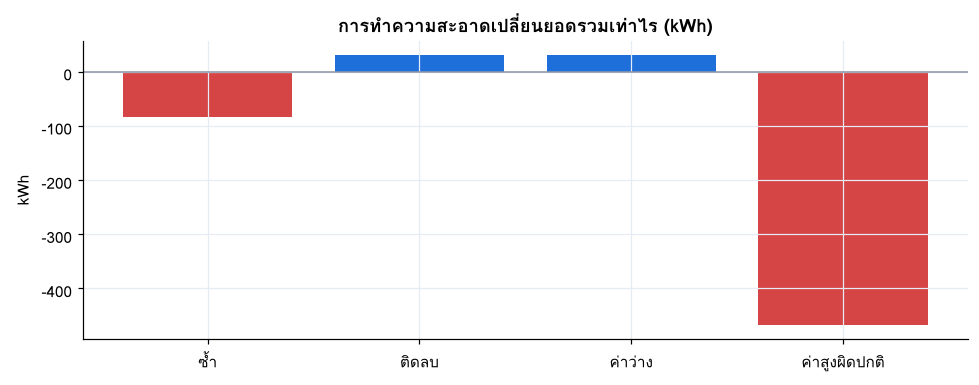

> **สรุปสั้น (n=350400):** ยอดรวมจาก 275,240.0 เป็น 274,748.3 kWh (เปลี่ยน -0.18%) ทุกการเปลี่ยนอธิบายได้และยอดปิดตรง

<details><summary><b>▶ ดูรายละเอียดการวิเคราะห์ (กดเปิด/ปิด)</b></summary>

**🔍 สิ่งที่พบ:** ขั้นที่เปลี่ยนยอดมากที่สุดคือตัดค่าสูงผิดปกติ (-468.5 kWh) รองลงมาคือตัดแถวซ้ำ (-84.6 kWh) ส่วนการเติมค่าว่างเพิ่ม 30.9 kWh และแทนค่าติดลบเพิ่ม 30.55 kWh

**💡 ความหมาย:** ผลการทำความสะอาดไม่ทำให้ยอดรวมหรือค่าเฉลี่ยผิดเพี้ยนโดยไร้เหตุผล และสามารถตรวจย้อนกลับได้ทีละขั้น

**🎯 ข้อเสนอแนะ:** ใช้ตารางนี้เป็นหลักฐานตอบกรรมการว่าตัวเลขเปลี่ยนเพราะอะไร และเก็บค่าเดิมไว้ในคอลัมน์ energy_kwh

- ใช้ดูอะไร: ตรวจว่าตัวเลขรวมหลังทำความสะอาดอธิบายได้
- อ่านอย่างไร: แท่งแดงคือยอดที่ลดลง แท่งน้ำเงินคือยอดที่เพิ่มขึ้นจากการเติมหรือแทนค่า
- วิเคราะห์ด้วยวิธี: กระทบยอดทีละขั้นด้วยผลรวม kWh และตรวจว่ายอดสุดท้ายตรงกับตารางสะอาด

</details>

In [16]:
# reconcile total kWh stage by stage: every change must be explained
neg_m = df["flag_negative"]; out_m = df["flag_outlier"]; mis_m = df["flag_missing"]
raw_vals = df["energy_kwh"]
steps = [("1 raw file (incl. duplicates)", raw_total_kwh),
         ("2 remove %d duplicate rows" % dup_rows, -dup_kwh),
         ("3 negative values replaced (%d rows)" % neg_m.sum(), df.loc[neg_m, "energy_clean"].sum() - raw_vals[neg_m].sum()),
         ("4 missing values filled (%d rows)" % mis_m.sum(), df.loc[mis_m, "energy_clean"].sum()),
         ("5 spikes replaced (%d rows)" % out_m.sum(), df.loc[out_m, "energy_clean"].sum() - raw_vals[out_m].sum())]
rec = pd.DataFrame(steps, columns=["stage", "delta_kWh"])
rec["running_total_kWh"] = rec["delta_kWh"].cumsum()
final_total = df["energy_clean"].sum()
rec.loc[len(rec)] = ["final energy_clean total (check)", np.nan, final_total]
display(rec.round(3))
assert abs(rec["running_total_kWh"].iloc[4] - final_total) < 1e-3, "reconciliation does not close"
print("reconciliation closes. rows: raw %d -> clean %d (= %d meters x %d hours)" % (n_raw, len(df), df["meter_id"].nunique(), expected_hours))

fig, ax = plt.subplots(figsize=(9, 3.6))
lab = ["ซ้ำ", "ติดลบ", "ค่าว่าง", "ค่าสูงผิดปกติ"]
vals = rec["delta_kWh"].iloc[1:5].values
ax.bar(lab, vals, color=[RED if x < 0 else BLUE for x in vals])
ax.axhline(0, color=GREY, lw=1); ax.set_ylabel("kWh"); ax.set_title("การทำความสะอาดเปลี่ยนยอดรวมเท่าไร (kWh)")
plt.tight_layout(); plt.show()
explain(
    short="ยอดรวมจาก %s เป็น %s kWh (เปลี่ยน %.2f%%) ทุกการเปลี่ยนอธิบายได้และยอดปิดตรง" % (format(round(raw_total_kwh, 1), ","), format(round(final_total, 1), ","), 100 * (final_total / raw_total_kwh - 1)),
    found="ขั้นที่เปลี่ยนยอดมากที่สุดคือตัดค่าสูงผิดปกติ (%.1f kWh) รองลงมาคือตัดแถวซ้ำ (%.1f kWh) ส่วนการเติมค่าว่างเพิ่ม %.1f kWh และแทนค่าติดลบเพิ่ม %.2f kWh" % (vals[3], vals[0], vals[2], vals[1]),
    meaning="ผลการทำความสะอาดไม่ทำให้ยอดรวมหรือค่าเฉลี่ยผิดเพี้ยนโดยไร้เหตุผล และสามารถตรวจย้อนกลับได้ทีละขั้น",
    action="ใช้ตารางนี้เป็นหลักฐานตอบกรรมการว่าตัวเลขเปลี่ยนเพราะอะไร และเก็บค่าเดิมไว้ในคอลัมน์ energy_kwh",
    use="ตรวจว่าตัวเลขรวมหลังทำความสะอาดอธิบายได้", read="แท่งแดงคือยอดที่ลดลง แท่งน้ำเงินคือยอดที่เพิ่มขึ้นจากการเติมหรือแทนค่า",
    method="กระทบยอดทีละขั้นด้วยผลรวม kWh และตรวจว่ายอดสุดท้ายตรงกับตารางสะอาด", n=len(df))

# ขั้นที่ 5 พจนานุกรมข้อมูลและส่งออก

## 5.1 พจนานุกรมข้อมูล

In [17]:
# data dictionary of the clean table (every column that is exported)
EXPORT_COLS = ["reading_id", "timestamp", "date", "month", "hour", "dow", "day_type", "day_type_th", "is_off_hours",
               "meter_id", "room_id", "building_id", "building_name", "room_type", "area_m2", "capacity_people", "air_conditioner_count",
               "occupancy_people", "energy_kwh", "energy_clean", "cell_median", "flag_missing", "flag_negative", "flag_outlier", "flag_imputed",
               "temperature_c", "relative_humidity_percent"]
desc = {
 "reading_id": ("รหัสรายการอ่านมิเตอร์ (คีย์หลัก)", "text", "-"),
 "timestamp": ("เวลาเริ่มช่วง 1 ชั่วโมง เวลาไทย (ค.ศ.)", "datetime", "yyyy-mm-dd hh:mm:ss"),
 "date": ("วันที่", "text", "yyyy-mm-dd"), "month": ("เดือน 1-12", "int", "-"),
 "hour": ("ชั่วโมงของวัน 0-23", "int", "-"), "dow": ("วันในสัปดาห์ 0=จันทร์ ... 6=อาทิตย์", "int", "-"),
 "day_type": ("ประเภทวัน weekday/weekend (เสาร์-อาทิตย์ ไม่มีปฏิทินวันหยุดนักขัตฤกษ์)", "category", "-"),
 "day_type_th": ("ประเภทวัน ภาษาไทย", "category", "-"),
 "is_off_hours": ("นอกเวลาใช้งาน = จำนวนคนเป็น 0 (ค่าตั้งต้น)", "bool", "-"),
 "meter_id": ("รหัสมิเตอร์", "category", "-"), "room_id": ("รหัสห้อง", "category", "-"),
 "building_id": ("รหัสอาคาร", "category", "-"), "building_name": ("ชื่ออาคาร", "category", "-"),
 "room_type": ("ประเภทห้อง", "category", "-"), "area_m2": ("พื้นที่ห้อง", "int", "ตร.ม."),
 "capacity_people": ("ความจุห้อง", "int", "คน"), "air_conditioner_count": ("จำนวนเครื่องปรับอากาศ", "int", "เครื่อง"),
 "occupancy_people": ("จำนวนคนโดยประมาณในชั่วโมงนั้น", "int", "คน"),
 "energy_kwh": ("พลังงานรายชั่วโมงตามไฟล์ดิบ (มีค่าว่าง ติดลบ ค่าสูงผิดปกติ)", "float", "kWh"),
 "energy_clean": ("พลังงานรายชั่วโมงหลังทำความสะอาด ใช้วิเคราะห์", "float", "kWh"),
 "cell_median": ("ค่ากลางปกติของมิเตอร์เดียวกัน ชั่วโมงเดียวกัน ประเภทวันเดียวกัน", "float", "kWh"),
 "flag_missing": ("ค่าเดิมว่าง", "bool", "-"), "flag_negative": ("ค่าเดิมติดลบ", "bool", "-"),
 "flag_outlier": ("ค่าเดิมสูงผิดปกติ", "bool", "-"), "flag_imputed": ("ถูกแทนด้วยค่ากลาง (รวม 3 กรณี)", "bool", "-"),
 "temperature_c": ("อุณหภูมิภายนอก (ชุดเดียวทุกอาคาร)", "float", "องศาเซลเซียส"),
 "relative_humidity_percent": ("ความชื้นสัมพัทธ์ (ชุดเดียวทุกอาคาร)", "float", "ร้อยละ")}
final = df[EXPORT_COLS].copy()
dic = pd.DataFrame([{"column": c, "description": desc[c][0], "type": desc[c][1], "unit": desc[c][2],
                     "example": str(final[c].iloc[1000])} for c in EXPORT_COLS])
display(dic)
assert set(EXPORT_COLS) == set(desc), "dictionary does not cover every column"

,column,description,type,unit,example
0,reading_id,รหัสรายการอ่านมิเตอร์ (คีย์หลัก),text,-,E0001001
1,timestamp,เวลาเริ่มช่วง 1 ชั่วโมง เวลาไทย (ค.ศ.),datetime,yyyy-mm-dd hh:mm:ss,2025-01-02 01:00:00
2,date,วันที่,text,yyyy-mm-dd,2025-01-02
3,month,เดือน 1-12,int,-,1
4,hour,ชั่วโมงของวัน 0-23,int,-,1
5,dow,วันในสัปดาห์ 0=จันทร์ ... 6=อาทิตย์,int,-,3
6,day_type,ประเภทวัน weekday/weekend (เสาร์-อาทิตย์ ไม่มี...,category,-,weekday
7,day_type_th,ประเภทวัน ภาษาไทย,category,-,วันทำการ
8,is_off_hours,นอกเวลาใช้งาน = จำนวนคนเป็น 0 (ค่าตั้งต้น),bool,-,True
9,meter_id,รหัสมิเตอร์,category,-,M001


## 5.2 ส่งออกไฟล์ และตรวจไฟล์ที่ส่งออก

In [18]:
# export (UTF-8 with BOM so Excel on Windows shows Thai correctly)
final.to_csv(OUT + "electricity_clean.csv", index=False, encoding="utf-8-sig")
try:
    final.to_parquet(OUT + "electricity_clean.parquet", index=False)   # needs pyarrow; optional
    parquet_ok = True
except Exception as ex:
    parquet_ok = False
    print("parquet skipped:", type(ex).__name__)

out_log.to_csv(OUT + "outliers_log.csv", index=False, encoding="utf-8-sig")
dic.to_csv(OUT + "data_dictionary_clean.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(LOG).to_csv(OUT + "cleaning_log.csv", index=False, encoding="utf-8-sig")
rec.round(3).to_csv(OUT + "reconciliation.csv", index=False, encoding="utf-8-sig")
# small sample (first week, all meters) for quick tests
final[final["timestamp"] < "2025-01-08"].to_csv(OUT + "sample_first_week.csv", index=False, encoding="utf-8-sig")

# verify what was written
chk = pd.read_csv(OUT + "electricity_clean.csv", encoding="utf-8-sig")
print("re-read rows:", len(chk), "| columns:", chk.shape[1], "| energy_clean missing:", int(chk["energy_clean"].isna().sum()))
print("total kWh re-read vs in memory: %.3f vs %.3f" % (chk["energy_clean"].sum(), final["energy_clean"].sum()))
print("files in data_clean:", sorted(os.listdir(OUT)))
display(pd.DataFrame(LOG))

re-read rows: 350400 | columns: 27 | energy_clean missing: 0
total kWh re-read vs in memory: 274748.346 vs 274748.346
files in data_clean: ['cleaning_log.csv', 'data_dictionary_clean.csv', 'electricity_clean.csv', 'electricity_clean.parquet', 'outliers_log.csv', 'reconciliation.csv', 'sample_first_week.csv']


,step,issue,rows_affected,action
0,1,timestamp cannot be parsed,0,none found
1,1,duplicate rows (exact copies),100,"dropped, kept first copy"
2,2,energy_kwh missing,35,filled with median of same meter x hour x day ...
3,3,"negative energy_kwh (all equal -0.5, looks lik...",18,"treated as invalid, replaced by cell median, f..."
4,3,isolated spikes 24-34x normal (rule: Q3+3*IQR ...,21,kept in outliers_log.csv with raw value; repla...


## 5.3 ขั้นตอนทำซ้ำ (Pipeline) และเวอร์ชัน

In [19]:
# reproducibility: order of work, how to run, versions used
steps_tbl = pd.DataFrame([
    [1, "notebooks/01_cleaning.ipynb", "jupyter nbconvert --to notebook --execute --inplace 01_cleaning.ipynb", "data_raw/*.csv", "data_clean/*"],
    [2, "notebooks/02_explore.ipynb", "jupyter nbconvert --to notebook --execute --inplace 02_explore.ipynb", "data_clean/electricity_clean.csv", "data_clean/*_summary.csv, problems.csv"]],
    columns=["order", "notebook", "run command", "reads", "writes"])
display(steps_tbl)
ver = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__}
import matplotlib; ver["matplotlib"] = matplotlib.__version__
print(ver)
with open("../requirements.txt", "w", encoding="utf-8") as f:
    f.write("pandas\nnumpy\nmatplotlib\nseaborn\nstatsmodels\nscipy\npyarrow\njupyter\nnbconvert\nipykernel\n")
print("folder structure: data_raw/ (given) | data_clean/ (output) | notebooks/ | tools/helpers.py | requirements.txt")

,order,notebook,run command,reads,writes
0,1,notebooks/01_cleaning.ipynb,jupyter nbconvert --to notebook --execute --in...,data_raw/*.csv,data_clean/*
1,2,notebooks/02_explore.ipynb,jupyter nbconvert --to notebook --execute --in...,data_clean/electricity_clean.csv,"data_clean/*_summary.csv, problems.csv"


{'python': '3.12.3', 'pandas': '3.0.6', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}
folder structure: data_raw/ (given) | data_clean/ (output) | notebooks/ | tools/helpers.py | requirements.txt


# คำถามที่กรรมการอาจถาม

In [20]:
# answers are built from the numbers computed above (no typed-in figures)
qa = [
 ("ข้อมูลมีปัญหาอะไรบ้าง และจัดการอย่างไร",
  "แถวซ้ำ %d แถว ตัดทิ้ง | ค่าว่าง %d แถว เติมด้วยค่ากลางของมิเตอร์เดียวกัน ชั่วโมงเดียวกัน ประเภทวันเดียวกัน | ค่าติดลบ %d แถว (เท่ากับ -0.5 ทุกแถว) ถือเป็นค่าเสีย | ค่าสูงผิดปกติ %d จุด ไม่ลบทิ้ง เก็บค่าเดิมและติดป้าย" % (dup_rows, len(na_rows), int(neg.sum()), len(out_log))),
 ("ทำไมไม่ใช้เกณฑ์ IQR รวมทั้งชุดตรวจค่าผิดปกติ",
  "เพราะการใช้ไฟมี 2 โหมด (ช่วงใช้งานกับนอกเวลา) เกณฑ์รวมจะติดป้ายผิดกับชั่วโมงปกติ %d แถว (%.1f%%) จึงเทียบกับกลุ่มของตัวเอง (มิเตอร์ x ชั่วโมง x วันทำการ/วันหยุด)" % (int(global_flag.sum()), 100 * global_flag.mean())),
 ("ทำไมไม่ลบค่าผิดปกติทั้งหมด",
  "ข้อมูลยังบอกไม่ได้ว่าเป็นความผิดพลาดหรือเหตุการณ์จริง จึงเก็บค่าเดิมไว้ในคอลัมน์ energy_kwh และ outliers_log.csv ใช้ค่าปกติแทนเฉพาะคอลัมน์ energy_clean และกระทบยอดรวม %.3f%%" % (100 * (final_total / raw_total_kwh - 1))),
 ("เติมค่าว่างกระทบสถิติไหม",
  "ยอดรวมเปลี่ยน %.4f%% และค่าเฉลี่ยเปลี่ยน %.4f%% (n=%d แถวที่เติม)" % (stat.loc["total_kWh", "change_pct"], stat.loc["mean_kWh", "change_pct"], len(na_rows))),
 ("นิยาม นอกเวลา คืออะไร",
  "ค่าตั้งต้นคือชั่วโมงที่จำนวนคนเป็น 0 ซึ่งตรงกับเวลา 08:00-16:59 วันจันทร์-ศุกร์ในข้อมูล %.2f%% ของแถว (ไม่มีปฏิทินวันหยุดนักขัตฤกษ์ในข้อมูล)" % (100 * match)),
 ("ข้อมูลเชื่อมกันครบไหม",
  "ทุกตารางเชื่อมกันได้ครบ (ต่ำสุด %.2f%%) และทุกมิเตอร์มี %s ชั่วโมงครบหลังตัดแถวซ้ำ" % (fk_table["match_rate_pct"].min(), format(expected_hours, ","))),
 ("ทำซ้ำได้อย่างไร",
  "รัน 01_cleaning แล้ว 02_explore ตามตารางขั้นตอน ไลบรารีอยู่ใน requirements.txt ข้อมูลผลลัพธ์อยู่ใน data_clean"),
]
for q, a in qa:
    md("**ถาม: %s**\n\nตอบ: %s\n" % (q, a))

**ถาม: ข้อมูลมีปัญหาอะไรบ้าง และจัดการอย่างไร**

ตอบ: แถวซ้ำ 100 แถว ตัดทิ้ง | ค่าว่าง 35 แถว เติมด้วยค่ากลางของมิเตอร์เดียวกัน ชั่วโมงเดียวกัน ประเภทวันเดียวกัน | ค่าติดลบ 18 แถว (เท่ากับ -0.5 ทุกแถว) ถือเป็นค่าเสีย | ค่าสูงผิดปกติ 21 จุด ไม่ลบทิ้ง เก็บค่าเดิมและติดป้าย


**ถาม: ทำไมไม่ใช้เกณฑ์ IQR รวมทั้งชุดตรวจค่าผิดปกติ**

ตอบ: เพราะการใช้ไฟมี 2 โหมด (ช่วงใช้งานกับนอกเวลา) เกณฑ์รวมจะติดป้ายผิดกับชั่วโมงปกติ 9208 แถว (2.6%) จึงเทียบกับกลุ่มของตัวเอง (มิเตอร์ x ชั่วโมง x วันทำการ/วันหยุด)


**ถาม: ทำไมไม่ลบค่าผิดปกติทั้งหมด**

ตอบ: ข้อมูลยังบอกไม่ได้ว่าเป็นความผิดพลาดหรือเหตุการณ์จริง จึงเก็บค่าเดิมไว้ในคอลัมน์ energy_kwh และ outliers_log.csv ใช้ค่าปกติแทนเฉพาะคอลัมน์ energy_clean และกระทบยอดรวม -0.179%


**ถาม: เติมค่าว่างกระทบสถิติไหม**

ตอบ: ยอดรวมเปลี่ยน 0.0112% และค่าเฉลี่ยเปลี่ยน 0.0013% (n=35 แถวที่เติม)


**ถาม: นิยาม นอกเวลา คืออะไร**

ตอบ: ค่าตั้งต้นคือชั่วโมงที่จำนวนคนเป็น 0 ซึ่งตรงกับเวลา 08:00-16:59 วันจันทร์-ศุกร์ในข้อมูล 100.00% ของแถว (ไม่มีปฏิทินวันหยุดนักขัตฤกษ์ในข้อมูล)


**ถาม: ข้อมูลเชื่อมกันครบไหม**

ตอบ: ทุกตารางเชื่อมกันได้ครบ (ต่ำสุด 100.00%) และทุกมิเตอร์มี 8,760 ชั่วโมงครบหลังตัดแถวซ้ำ


**ถาม: ทำซ้ำได้อย่างไร**

ตอบ: รัน 01_cleaning แล้ว 02_explore ตามตารางขั้นตอน ไลบรารีอยู่ใน requirements.txt ข้อมูลผลลัพธ์อยู่ใน data_clean
